# 01. 탐색적 데이터 분석 (EDA)

서울교통공사 1~8호선 30분 단위 혼잡도(2026-09-30 기준)와 역간 소요시간 데이터를 살펴보고, 정제 규칙을 정한다.
여기서 정한 규칙은 `src/subway/clean.py`에 함수로 옮겨 이후 분석이 모두 같은 데이터를 쓰게 한다.

**혼잡도** = 탑승 인원 ÷ 정원(칸당 160명) × 100. 34%면 좌석이 다 찬 수준, 100%면 정원만큼 탄 상태다.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from subway.load import load_congestion, load_travel_time
from subway.clean import clean_congestion, find_structural_zeros
from subway.config import COMMUTE_WINDOWS

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid", font="Malgun Gothic", rc={"axes.unicode_minus": False})
pd.set_option("display.max_columns", 20)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

raw = load_congestion(RAW / "서울교통공사_지하철혼잡도정보_20260930.csv")
tt = load_travel_time(RAW / "서울교통공사 역간거리 및 소요시간_240810.csv")
raw.head()

,day_type,line,station_code,station,direction,congestion,hour
0,평일,1,150,서울역,상선,8.9,5.5
1,평일,1,150,서울역,하선,11.5,5.5
2,평일,1,151,시청,상선,7.3,5.5
3,평일,1,151,시청,하선,9.2,5.5
4,평일,1,152,종각,상선,6.8,5.5


## 1. 데이터 구조

In [2]:
print(f"행 {len(raw):,}개 | 노선 {raw.line.nunique()}개 | 역 {raw.station.nunique()}개 | 시간대 {raw.hour.nunique()}개")
print("결측:", raw.congestion.isna().sum())
raw.groupby(["day_type", "direction"]).size().unstack()

행 65,169개 | 노선 8개 | 역 245개 | 시간대 39개
결측: 0


direction,내선,상선,외선,하선
day_type,,,,
일요일,2106,8619,2106,8892
토요일,2106,8619,2106,8892
평일,2106,8619,2106,8892


- 원본 파일은 결측이 없다. 하지만 **0값이 5.7%** 있어서 실제로는 '값 없음'이 0으로 들어가 있을 가능성이 높다.
- 2호선(순환선)은 방향을 `내선/외선`, 나머지 노선은 `상선/하선`으로 표기한다.
- 하선 행이 상선보다 많다. 즉 어떤 역은 한 방향 데이터만 있다.

In [3]:
one_way = raw[raw.day_type == "평일"].groupby(["line", "station"]).direction.nunique()
one_way[one_way < 2]

line  station  
5     강동           1
      강동(마천)       1
      강동(하남검단산)    1
6     구산           1
      독바위          1
      불광           1
      역촌           1
      연신내          1
      응암S          1
Name: direction, dtype: int64

한 방향만 있는 역은 두 종류다.
- **5호선 강동 분기**: `강동(마천)`, `강동(하남검단산)`처럼 분기 방향별로 행이 나뉘어 있다.
- **6호선 응암순환**: 응암→역촌→불광→독바위→연신내→구산→응암은 한 방향으로만 도는 구간이다.

데이터 오류가 아니라 노선 구조를 반영한 것이므로 그대로 둔다.

## 2. 0값의 정체

In [4]:
zeros = find_structural_zeros(raw)
print(f"하루 종일 0인 역·방향: {len(zeros)}개")
zeros.query("day_type == '평일'")

하루 종일 0인 역·방향: 42개


,day_type,line,station_code,station,direction
28,평일,2,211,성수,외선
29,평일,2,246,신설동,외선
30,평일,2,260,까치산,내선
31,평일,2,9001,성수E,내선
32,평일,2,9002,성수,내선
33,평일,2,9003,신도림,외선
34,평일,3,342,오금,하선
35,평일,5,2511,방화,상선
36,평일,5,2561,마천,하선
37,평일,5,2566,하남검단산,하선


하루 종일 0인 시리즈는 대부분 **종착역에서 더 갈 곳이 없는 방향**이다(예: 오금 하선, 마천 하선, 방화 상선, 신설동·까치산 같은 지선 끝 역).
'혼잡도 0%'가 아니라 '측정 대상 열차 없음'이므로 분석에서 빼야 한다. 그대로 두면 평균 혼잡도가 낮게 나온다.

> 예외로 **2호선 성수(211) 외선**은 본선 역인데도 하루 종일 0이다. 성수지선 출발 행(9002)의 내선도 함께 0이라, 원자료에서 두 행의 방향 집계가 엇갈린 것으로 보인다.
> 원인은 확인하지 못했다. 다만 값이 없다는 점은 같으므로 똑같이 제외하고, 한계로 기록해 둔다.

> 성수·신도림은 본선 행과 지선 출발 행이 **역명은 같고 역번호(9002, 9003)만 다르다.**
> 처음에 역명으로만 묶었을 때는 두 행이 섞여 0 비율이 52%로 나와서 종착 방향을 찾지 못했다. 역번호까지 키로 써서 해결했다.

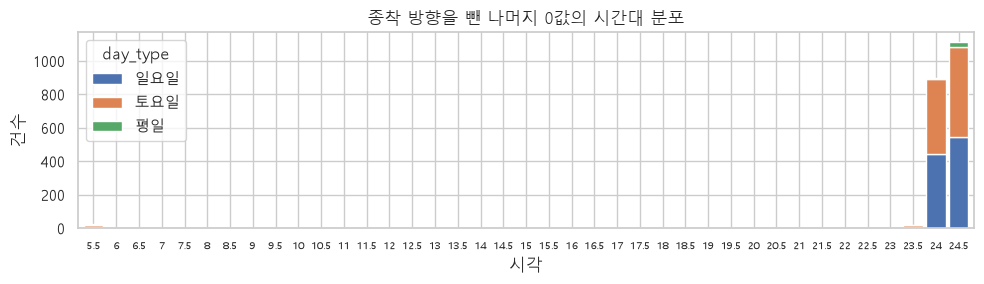

0을 뺀 최솟값: 0.1


In [5]:
rest = raw.merge(zeros, how="left", indicator=True).query("_merge == 'left_only'")
z = rest[rest.congestion == 0]
fig, ax = plt.subplots(figsize=(10, 3))
z.groupby(["hour", "day_type"]).size().unstack(fill_value=0).reindex(sorted(raw.hour.unique()), fill_value=0).plot.bar(stacked=True, ax=ax, width=0.85)
ax.set(title="종착 방향을 뺀 나머지 0값의 시간대 분포", xlabel="시각", ylabel="건수")
ax.set_xticklabels([f"{h:g}" for h in sorted(raw.hour.unique())], rotation=0, fontsize=7)
plt.tight_layout(); plt.show()
print("0을 뺀 최솟값:", rest.loc[rest.congestion > 0, "congestion"].min())

나머지 0값은 **자정 이후(24시, 24.5시)와 주말 첫차·막차 무렵**에만 몰려 있다. 운행이 끝났거나 시작하지 않은 시간이다.
0이 아닌 값은 최소 0.1%까지 내려가지만, 0은 운행 시간 경계에만 나타난다. 그래서 남은 0은 모두 NaN(미운행)으로 바꾼다.

> 원본 프로젝트는 결측을 **중앙값으로 채웠다.** 이 데이터에서는 그렇게 하면 '열차가 없는 시간'에 가짜 혼잡도가 생긴다.

## 3. 정제 적용

In [6]:
df = clean_congestion(raw)
print(f"{len(raw):,}행 → {len(df):,}행 (종착 방향 {len(zeros)}개 시리즈 제거), 미운행 NaN {df.congestion.isna().sum():,}개")
df.congestion.describe().round(1)

65,169행 → 63,531행 (종착 방향 42개 시리즈 제거), 미운행 NaN 2,055개


count    61476.0
mean        30.6
std         19.5
min          0.1
25%         15.7
50%         27.9
75%         41.4
max        146.3
Name: congestion, dtype: float64

## 4. 요일별 하루 혼잡도 곡선

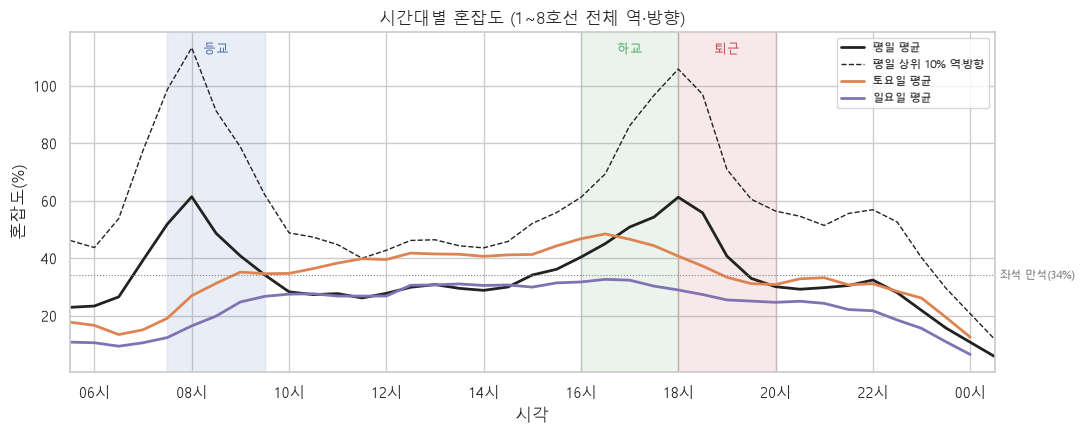

In [7]:
def shade_windows(ax):
    colors = {"등교": "#4c72b0", "하교": "#55a868", "퇴근": "#c44e52"}
    for name, (s, e) in COMMUTE_WINDOWS.items():
        ax.axvspan(s, e, color=colors[name], alpha=0.12)
        ax.text((s + e) / 2, ax.get_ylim()[1] * 0.97, name, ha="center", va="top", fontsize=9, color=colors[name])

profile = df.groupby(["day_type", "hour"]).congestion.agg(["mean", lambda s: s.quantile(0.9)]).reset_index()
profile.columns = ["day_type", "hour", "평균", "상위10%"]

fig, ax = plt.subplots(figsize=(11, 4.5))
for day, color in zip(["평일", "토요일", "일요일"], ["#222", "#dd8452", "#8172b3"]):
    p = profile[profile.day_type == day]
    ax.plot(p.hour, p["평균"], color=color, lw=2, label=f"{day} 평균")
    if day == "평일":
        ax.plot(p.hour, p["상위10%"], color=color, lw=1, ls="--", label="평일 상위 10% 역·방향")
ax.axhline(34, color="gray", lw=0.8, ls=":"); ax.text(24.6, 34, "좌석 만석(34%)", va="center", fontsize=8, color="gray")
ax.set(xlabel="시각", ylabel="혼잡도(%)", xlim=(5.5, 24.5), title="시간대별 혼잡도 (1~8호선 전체 역·방향)")
ax.set_xticks(range(6, 25, 2)); ax.set_xticklabels([f"{h % 24:02d}시" for h in range(6, 25, 2)])
shade_windows(ax); ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "01_daily_profile.png", dpi=150); plt.show()

In [8]:
wk = profile[profile.day_type == "평일"].set_index("hour")
for name, (s, e) in COMMUTE_WINDOWS.items():
    w = wk.loc[s:e - 0.5]
    print(f"{name} {s:g}~{e:g}시: 평균 {w['평균'].mean():.1f}%, 피크 {w['평균'].idxmax():g}시 {w['평균'].max():.1f}%, 상위10% 역 피크 {w['상위10%'].max():.1f}%")

등교 7.5~9.5시: 평균 50.7%, 피크 8시 61.4%, 상위10% 역 피크 113.2%
하교 16~18시: 평균 47.6%, 피크 17.5시 54.3%, 상위10% 역 피크 96.6%
퇴근 18~20시: 평균 47.7%, 피크 18시 61.2%, 상위10% 역 피크 105.8%


- 평일은 **08:00(등교)과 18:00(퇴근)** 두 봉우리가 거의 같은 높이다.
- 주말은 출퇴근 봉우리가 없고 오후(16~17시)에 완만하게 높다. 토요일이 일요일보다 훨씬 붐빈다.
- 전체 평균은 피크 때도 61% 남짓이지만, 상위 10% 역·방향은 등교 피크에 **113%**, 퇴근 피크에 106%까지 올라간다. **평균만 보면 실제 체감 혼잡을 크게 과소평가한다.**

> 원본 발표의 등교 평균 28%는 등교 구간을 05:30~14:30으로 넓게 잡아서 나온 값이다. 피크 2시간만 보면 이보다 훨씬 높다.

## 5. 노선별 차이

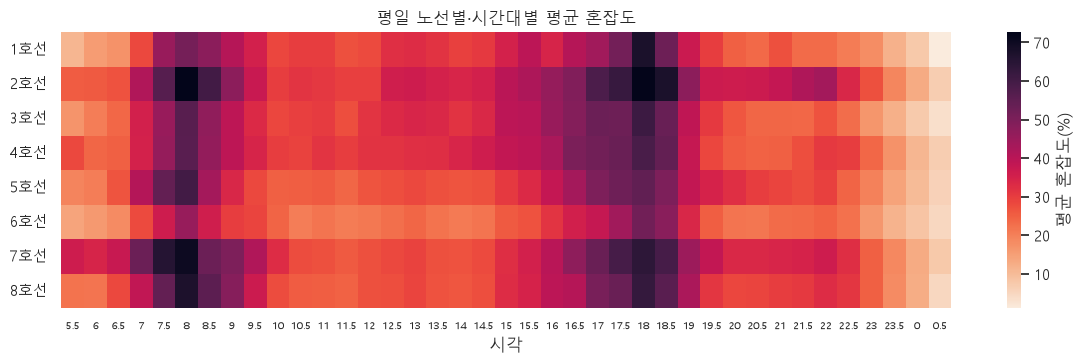

In [9]:
heat = df[df.day_type == "평일"].pivot_table(index="line", columns="hour", values="congestion", aggfunc="mean")
fig, ax = plt.subplots(figsize=(12, 3.8))
sns.heatmap(heat, cmap="rocket_r", ax=ax, cbar_kws={"label": "평균 혼잡도(%)"})
ax.set_xticklabels([f"{float(t.get_text()) % 24:g}" for t in ax.get_xticklabels()], rotation=0, fontsize=7)
ax.set_yticklabels([f"{int(float(t.get_text()))}호선" for t in ax.get_yticklabels()], rotation=0)
ax.set(xlabel="시각", ylabel="", title="평일 노선별·시간대별 평균 혼잡도")
plt.tight_layout(); plt.savefig(FIG / "02_line_heatmap.png", dpi=150); plt.show()

## 6. 방향을 평균하면 안 되는 이유

In [10]:
wk = df[df.day_type == "평일"]
def dir_gap(h):
    p = wk[wk.hour == h].pivot_table(index=["line", "station_code", "station"], columns="direction", values="congestion")
    pairs = [("상선", "하선"), ("내선", "외선")]
    gaps = pd.concat([(p[a] - p[b]).abs().dropna() for a, b in pairs])
    return gaps
for h in [8.0, 18.0]:
    g = dir_gap(h)
    print(f"{h:g}시: 같은 역 양방향 혼잡도 차이 중앙값 {g.median():.1f}%p, 30%p 이상인 역 {(g >= 30).mean():.0%}")

8시: 같은 역 양방향 혼잡도 차이 중앙값 40.7%p, 30%p 이상인 역 64%
18시: 같은 역 양방향 혼잡도 차이 중앙값 34.7%p, 30%p 이상인 역 56%


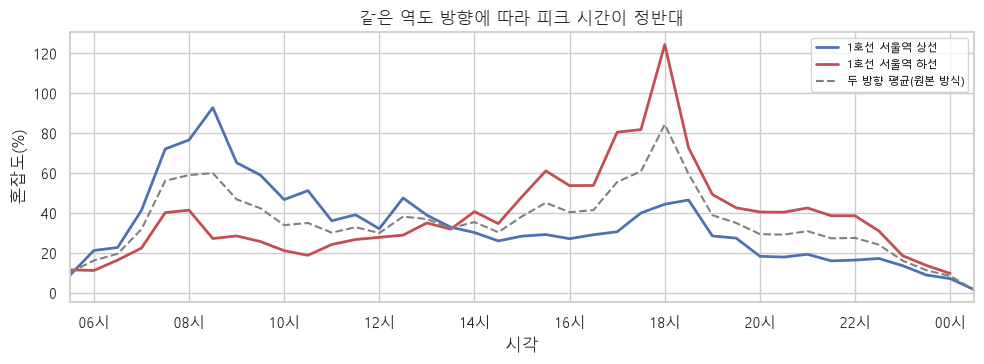

In [11]:
ex = wk[(wk.station == "서울역") & (wk.line == 1)]
fig, ax = plt.subplots(figsize=(10, 3.8))
for d, c in [("상선", "#4c72b0"), ("하선", "#c44e52")]:
    s = ex[ex.direction == d]; ax.plot(s.hour, s.congestion, label=f"1호선 서울역 {d}", color=c, lw=2)
avg = ex.groupby("hour").congestion.mean(); ax.plot(avg.index, avg.values, color="gray", ls="--", label="두 방향 평균(원본 방식)")
ax.set(xlabel="시각", ylabel="혼잡도(%)", xlim=(5.5, 24.5), title="같은 역도 방향에 따라 피크 시간이 정반대")
ax.set_xticks(range(6, 25, 2)); ax.set_xticklabels([f"{h % 24:02d}시" for h in range(6, 25, 2)]); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "03_direction_example.png", dpi=150); plt.show()

서울역 1호선은 **아침에는 상선(시내 방향), 저녁에는 하선(외곽 방향)**이 붐빈다. 두 방향을 평균하면 양쪽 피크가 모두 반으로 깎인다.
원본 프로젝트는 방향을 구분하지 않고 역 단위로 평균했다. 이 프로젝트에서는 **역·방향을 분석 단위**로 쓴다.

## 7. 평일 등교·하교 시간대에 가장 붐비는 역·방향

In [12]:
def top_in_window(name, n=10):
    s, e = COMMUTE_WINDOWS[name]
    w = wk[(wk.hour >= s) & (wk.hour < e)]
    return (w.groupby(["line", "station", "direction"]).congestion.agg(평균="mean", 최고="max")
             .round(1).sort_values("평균", ascending=False).head(n).reset_index())
top_am, top_pm = top_in_window("등교"), top_in_window("하교")
display(top_am); display(top_pm)

,line,station,direction,평균,최고
0,8,몽촌토성,하선,137.6,144.6
1,2,사당,외선,137.3,144.8
2,7,군자,하선,136.0,143.6
3,8,강동구청,하선,134.8,145.7
4,7,어린이대공원,하선,134.0,142.5
5,7,중곡,하선,133.2,144.0
6,2,방배,외선,131.8,142.0
7,8,천호,하선,130.7,140.7
8,7,용마산,하선,127.9,142.7
9,7,철산,상선,126.4,145.5


,line,station,direction,평균,최고
0,2,방배,내선,111.5,141.9
1,2,서초,내선,109.8,138.8
2,2,교대,내선,105.9,134.2
3,2,강남,내선,104.8,125.4
4,4,동대문,상선,96.1,113.2
5,5,길동,하선,95.8,129.3
6,2,사당,내선,95.4,122.4
7,7,건대입구,상선,94.6,131.5
8,4,동대문역사문화공원,상선,94.5,112.8
9,2,역삼,내선,94.2,115.5


- **등교**: 7호선 용마산~어린이대공원 하선(강남 방향), 8호선 천호~몽촌토성 하선(잠실 방향), 2호선 사당·방배 외선(강남 방향)이 평균 125~138%로 가장 붐빈다. 주거지에서 강남·잠실 업무지구로 들어가는 방향이다.
- **하교**: 2호선 방배·서초·교대·강남 **내선**이 평균 105~112%로 상위를 차지한다. 아침에 붐비던 구간이 저녁에는 반대 방향으로 붐빈다.
- 등교 상위 10곳이 모두 평균 125%를 넘는다. 원본의 '등교 평균 28%'와는 다른 그림이다.

## 8. 환승역 판별의 한계

In [13]:
lines_per_station = df.groupby("station").line.nunique()
in_data = set(lines_per_station[lines_per_station > 1].index)
print(f"이 데이터(1~8호선)만으로 찾은 환승역: {len(in_data)}개")

# 1~8호선 밖의 노선(코레일, 9호선, 신분당선, 공항철도 등)과 환승하는 역 일부
external = {
    "신도림": "1호선(코레일)", "가산디지털단지": "1호선(코레일)", "홍대입구": "공항철도·경의중앙선",
    "디지털미디어시티": "공항철도·경의중앙선", "당산": "9호선", "여의도": "9호선",
    "김포공항": "9호선·공항철도", "선릉": "수인분당선", "강남": "신분당선",
}
pd.DataFrame([{"역": s, "다른 노선": l, "데이터로 환승역 판별": s in in_data} for s, l in external.items()])

이 데이터(1~8호선)만으로 찾은 환승역: 34개


,역,다른 노선,데이터로 환승역 판별
0,신도림,1호선(코레일),False
1,가산디지털단지,1호선(코레일),False
2,홍대입구,공항철도·경의중앙선,False
3,디지털미디어시티,공항철도·경의중앙선,False
4,당산,9호선,False
5,여의도,9호선,False
6,김포공항,9호선·공항철도,False
7,선릉,수인분당선,False
8,강남,신분당선,False


원본처럼 '1~8호선 안에서 역명이 겹치는지'로 환승역을 정하면, 실제로 환승객이 많은 **신도림·홍대입구·강남·선릉** 같은 역이 '일반역'으로 분류된다.
원본 결론인 "환승역보다 상권이 중요하다"(클러스터 0: 강남 등 '환승 없는 일반역')는 이 오분류 때문에 나왔을 가능성이 크다.
→ 회귀·군집 분석 전에 **전체 수도권 노선 기준 환승역 목록**을 따로 만든다.

## 9. 역간 소요시간 데이터와의 연결

In [14]:
a = set(zip(df.line, df.station)); b = set(zip(tt.line, tt.station))
print("혼잡도에만 있는 (노선, 역):", a - b)
print("소요시간에만 있는 (노선, 역):", b - a)
print(f"구간 소요시간: 평균 {tt.loc[tt.minutes > 0, 'minutes'].mean():.2f}분, 범위 {tt.loc[tt.minutes > 0, 'minutes'].min():.1f}~{tt.minutes.max():.1f}분")
tt[tt.minutes == 0]

혼잡도에만 있는 (노선, 역): set()
소요시간에만 있는 (노선, 역): set()
구간 소요시간: 평균 1.56분, 범위 1.0~4.5분


,seq,line,station,distance_km,cum_km,minutes
0,1,1,서울역,0.0,0.0,0.0
10,11,2,시청,0.0,0.0,0.0
62,63,3,지축,0.0,0.0,0.0
96,97,4,불암산,0.0,0.0,0.0
122,123,5,방화,0.0,0.0,0.0
178,179,6,응암,0.0,0.0,0.0
218,219,7,장암,0.0,0.0,0.0
260,261,8,암사역사공원,0.0,0.0,0.0


- 역명 표기 차이(`신촌(지하)`, `올림픽공원(한국체대)`, `당고개→불암산` 등)를 `config.STATION_ALIASES`로 맞춰서 두 데이터가 **모두 일치**한다.
- 원본 추천 프로그램은 구간마다 5분을 가정했다. 실제 구간 소요시간은 **평균 약 1.5분**이라, 5분 가정은 이동 시간을 3배 넘게 부풀린다. 10개 역을 지나면 30분 이상 어긋나서 다른 시간대의 혼잡도를 조회하게 된다.
- 소요시간이 0인 행은 노선·지선의 시작점이다. 파일이 '바로 윗행 역 → 이 역' 순서로 되어 있어서, 지선(2호선 성수·신정지선, 5호선 마천지선, 6호선 응암순환)은 **연결 지점을 따로 지정**해야 한다. 경로 그래프를 만들 때 처리한다.

## 정리

| 발견 | 처리 |
|---|---|
| 종착 방향 등 42개 시리즈가 하루 종일 0 (성수 211 외선은 원인 미확인) | 분석에서 제외 |
| 나머지 0은 첫차 전·막차 후 | NaN(미운행) 처리, 중앙값 대체 안 함 |
| 같은 역도 방향별 피크가 정반대 | 역·방향을 분석 단위로 사용 |
| 평균은 상위 역의 피크를 가림 | 평균과 함께 상위 분위수도 보고 |
| 1~8호선만으로 환승역 판별 시 주요 환승역 누락 | 외부 노선 포함 환승역 목록 별도 구축 |
| 실제 구간 소요시간 평균 약 1.5분 (원본 가정 5분) | 소요시간 데이터로 경로 시뮬레이션 |

다음 노트북: `02_commute_comparison.ipynb`에서 등교·하교·퇴근 시간대 차이를 역·방향 단위 대응표본 검정으로 비교한다.